# **Predictive Modeling Using Machine Learning**

## 1. Project Overview

This project focuses on building a Machine Learning model to predict flower species using the Iris dataset.

A Decision Tree Classifier is used to train the model and predict the species based on flower measurements.

The model performance is evaluated using accuracy and a confusion matrix.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Loading the Dataset

The Iris dataset contains 150 flower records with four numerical features and one target column representing the flower species.

The dataset is used to train a Machine Learning classification model.

In [10]:
df = pd.read_csv('/content/iris.csv', header=None)

df.columns = [
    'SepalLength',
    'SepalWidth',
    'PetalLength',
    'PetalWidth',
    'Species'
]

df.head()

,SepalLength,SepalWidth,PetalLength,PetalWidth,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Data Inspection

The dataset is inspected to understand its structure, number of records, column data types, and missing values before training the Machine Learning model.

In [11]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nSpecies Distribution:")
print(df['Species'].value_counts())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SepalLength  150 non-null    float64
 1   SepalWidth   150 non-null    float64
 2   PetalLength  150 non-null    float64
 3   PetalWidth   150 non-null    float64
 4   Species      150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing Values:
SepalLength    0
SepalWidth     0
PetalLength    0
PetalWidth     0
Species        0
dtype: int64

Duplicate Records:
3

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 4. Splitting Data into Training and Testing

The dataset is divided into input features (X) and the target variable (y). The data is then split into 80% training data and 20% testing data.

The training data is used to teach the model, while the testing data is used to evaluate its performance.

In [12]:
X = df.drop('Species', axis=1)
y = df['Species']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


## 5. Model Training

A Decision Tree Classifier is used to train the Machine Learning model. It learns patterns from the training data to predict the species of Iris flowers.

In [13]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


## 6. Model Prediction

The trained Decision Tree model is used to predict Iris flower species using the testing data.

In [14]:
y_pred = model.predict(X_test)

print("Actual Species:")
print(y_test.values)

print("\nPredicted Species:")
print(y_pred)

Actual Species:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']

Predicted Species:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa'

## 7. Model Evaluation

The model is evaluated using accuracy score and a classification report. These metrics help us understand how correctly the model predicts Iris flower species.

In [15]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 93.33 %

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



## 8. Confusion Matrix

A confusion matrix is used to compare actual and predicted values. It helps identify how many predictions were correct and incorrect for each Iris species.

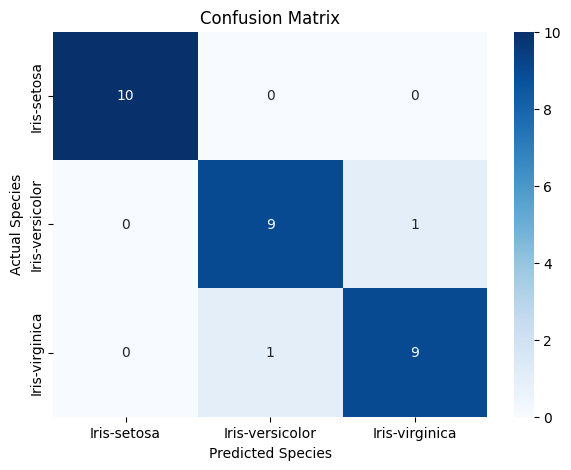

In [16]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

## 9. Key Findings

1. The dataset contains 150 records and 4 input features.
2. The dataset has three Iris flower species.
3. A Decision Tree Classifier was used for prediction.
4. The model achieved an accuracy of 93.33%.
5. Out of 30 test records, 28 were correctly classified.
6. Iris-setosa was classified correctly in all 10 test cases.
7. Two predictions were incorrect between Iris-versicolor and Iris-virginica.

## 10. Conclusion

In this project, a Decision Tree Classifier was developed to predict Iris flower species using supervised Machine Learning.

The dataset was divided into training and testing sets. The model was trained and evaluated using accuracy score, classification report, and confusion matrix.

The model achieved an accuracy of **93.33%**, correctly classifying 28 out of 30 test records.

This project helped demonstrate the basic workflow of supervised Machine Learning, including data preparation, model training, prediction, and evaluation.